# 📊 Retail Sales & Profitability Analysis
### End-to-End Data Analytics Portfolio Project | Python, Pandas, Matplotlib & Seaborn
---
**Author:** Data Analyst Portfolio  
**Date:** 2026  
**Dataset:** Retail Sales Transactions (2024 - 2025)  

## 1. Project Overview & Business Problem
Retail companies generate thousands of multi-channel transactions every day. While top-line gross sales are often tracked closely, businesses frequently struggle to understand **net profit realization**, the erosive effect of **promotional discounts**, and **geographic margin variations**.

### Core Objectives:
1. **Data Audit & Cleansing:** Identify and remediate duplicates, missing values, string anomalies, and date formatting inconsistencies.
2. **Financial KPI Engineering:** Derive Gross Sales, Discount Amounts, Net Revenue, Total Cost, Profit, and Profit Margin %.
3. **Trend & Seasonality Analysis:** Track 24-month revenue and profit trajectories to uncover seasonal peaks.
4. **Product & Category Intelligence:** Evaluate performance across categories and identify the top 10 revenue drivers.
5. **Regional Diagnostics:** Compare geographic performance and evaluate regional margin efficiency.
6. **Discount Optimization:** Analyze margin erosion across discount tiers to formulate actionable recommendations.

## 2. Environment Setup & Library Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'${x:,.2f}' if abs(x) > 1 else f'{x:.2f}')
print('Setup complete. Libraries successfully loaded.')

## 3. Data Ingestion & Initial Quality Assessment

In [2]:
raw_path = os.path.join('..', 'data', 'raw_retail_sales.csv')
df_raw = pd.read_csv(raw_path)
print(f'Raw Dataset Shape: {df_raw.shape}')
print(f'Duplicate Order IDs: {df_raw.duplicated(subset=["Order_ID"]).sum()}')
print('\nMissing Values by Column:')
print(df_raw.isnull().sum())

Raw Dataset Shape: (2435, 13)
Duplicate Order IDs: 35

Missing Values by Column:
Order_ID             0
Order_Date           0
Customer_ID          0
Customer_Segment    42
Region               0
Category             0
Sub_Category         0
Product_Name         0
Unit_Cost            0
Unit_Price           0
Quantity             0
Discount            30
Payment_Method      38
dtype: int64


## 4. Data Cleaning & Feature Engineering
- Remove 35 duplicate transactions.
- Impute missing categorical values (`Customer_Segment`, `Payment_Method`) using modal frequency.
- Impute missing `Discount` with `0.0`.
- Strip whitespace and standardize casing on textual columns.
- Parse mixed date strings into datetime format.
- Calculate financial KPIs: `Gross_Sales`, `Discount_Amount`, `Total_Revenue`, `Total_Cost`, `Profit`, and `Profit_Margin_Pct`.

In [3]:
clean_path = os.path.join('..', 'data', 'cleaned_retail_sales.csv')
df = pd.read_csv(clean_path)
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
print(f'Clean Dataset Shape: {df.shape}')
print(f'Remaining Nulls: {df.isnull().sum().sum()}')
print(f'Date Range: {df["Order_Date"].min().date()} to {df["Order_Date"].max().date()}')
print('\nFinancial Overview:')
print(f'Total Revenue:  ${df["Total_Revenue"].sum():,.2f}')
print(f'Total Net Profit: ${df["Profit"].sum():,.2f}')
print(f'Average Profit Margin: {(df["Profit"].sum() / df["Total_Revenue"].sum() * 100):.2f}%')

Clean Dataset Shape: (2400, 21)
Remaining Nulls: 0
Date Range: 2024-01-01 to 2025-12-31

Financial Overview:
Total Revenue:  $1,898,692.70
Total Net Profit: $643,326.70
Average Profit Margin: 33.88%


## 5. Executive Key Performance Indicators (KPIs)

In [4]:
kpi_df = pd.DataFrame({
    'Metric': [
        'Total Orders', 'Unique Customers', 'Total Units Sold',
        'Total Net Revenue', 'Total Cost of Goods (COGS)', 'Total Net Profit',
        'Average Order Value (AOV)', 'Blended Profit Margin'
    ],
    'Value': [
        f"{len(df):,}", f"{df['Customer_ID'].nunique():,}", f"{df['Quantity'].sum():,}",
        f"${df['Total_Revenue'].sum():,.2f}", f"${df['Total_Cost'].sum():,.2f}",
        f"${df['Profit'].sum():,.2f}", f"${df['Total_Revenue'].mean():,.2f}",
        f"{(df['Profit'].sum() / df['Total_Revenue'].sum() * 100):.2f}%"
    ]
})
kpi_df

Metric,Value
Total Orders,"2,400"
Unique Customers,448
Total Units Sold,"5,816"
Total Net Revenue,"$1,898,692.70"
Total Cost of Goods (COGS),"$1,255,366.00"
Total Net Profit,"$643,326.70"
Average Order Value (AOV),$791.12
Blended Profit Margin,33.88%


## 6. Monthly Revenue & Profit Trend Analysis
Tracking revenue alongside net profit across the 24-month horizon reveals whether sales spikes translate directly into bottom-line earnings.

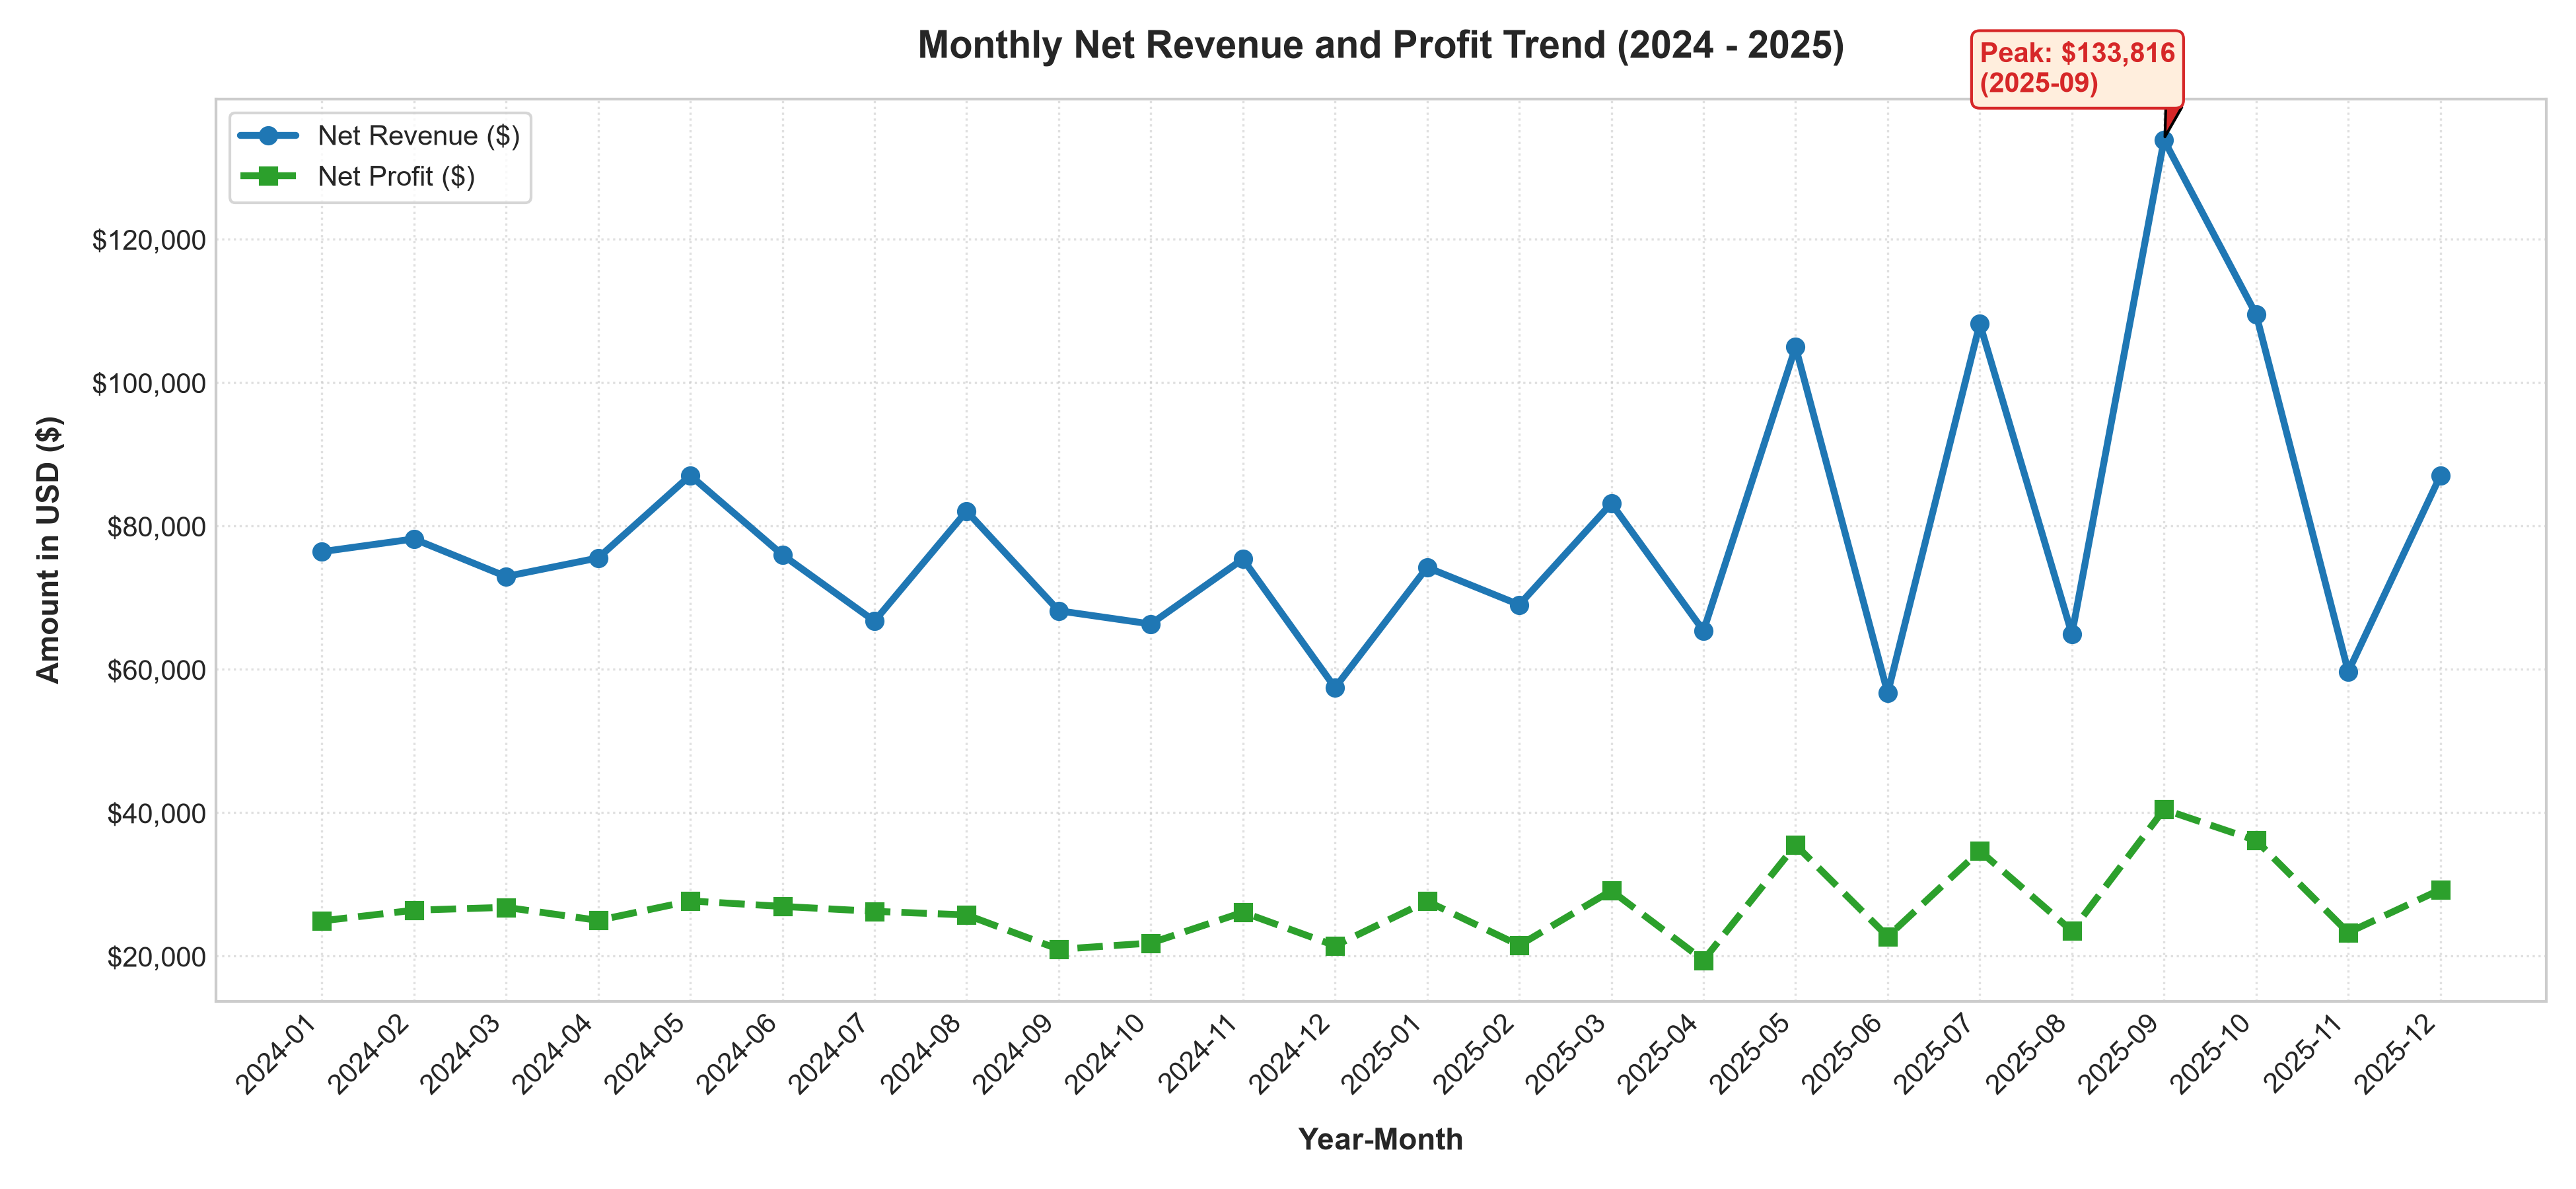

In [5]:
# Visualized from src/exploratory_analysis.py
monthly_sales = df.groupby('Year_Month').agg(
    Revenue=('Total_Revenue', 'sum'),
    Profit=('Profit', 'sum')
).reset_index()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly_sales['Year_Month'], monthly_sales['Revenue'], marker='o', color='#1f77b4', lw=2.5, label='Net Revenue')
ax.plot(monthly_sales['Year_Month'], monthly_sales['Profit'], marker='s', color='#2ca02c', lw=2.5, ls='--', label='Net Profit')
ax.set_title('Monthly Revenue and Profit Trajectory (2024 - 2025)', fontsize=14, weight='bold')
ax.set_ylabel('USD ($)')
ax.set_xticklabels(monthly_sales['Year_Month'], rotation=45, ha='right')
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

## 7. Product Category Performance: Revenue vs. Profit Margins
Understanding which categories drive high revenue volume versus high profitability margin.

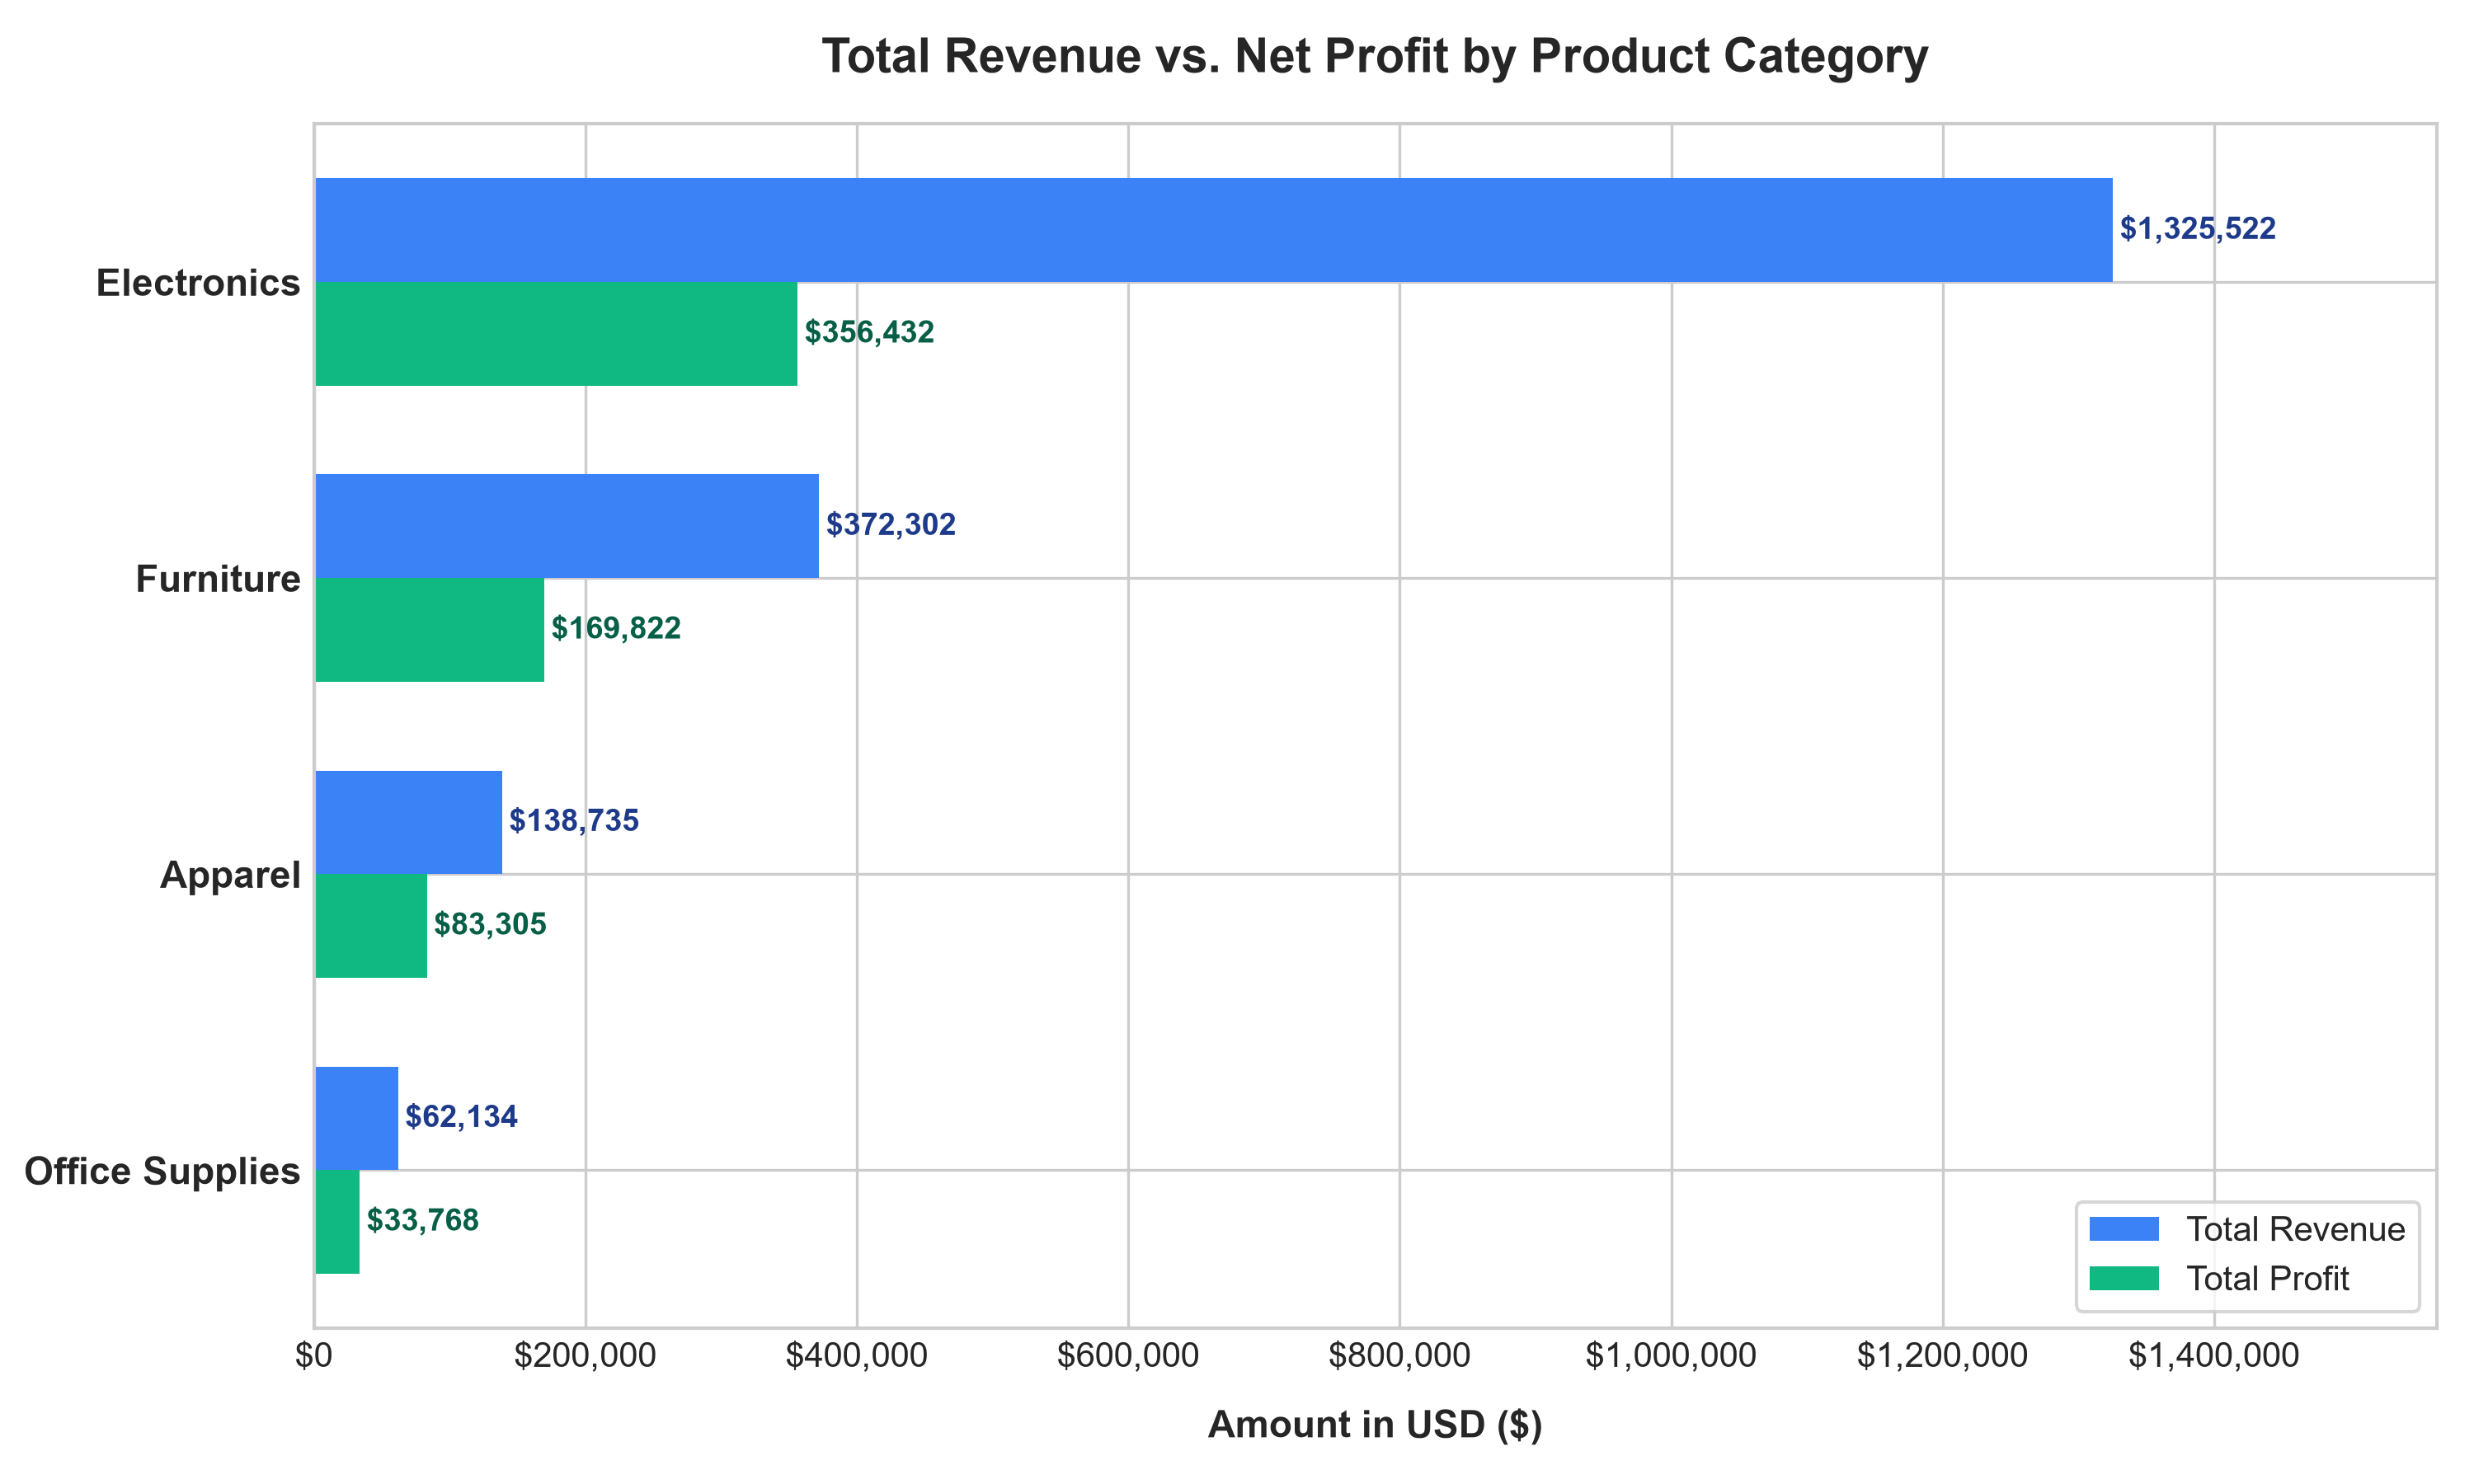

In [6]:
cat_perf = df.groupby('Category').agg(
    Revenue=('Total_Revenue', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order_ID', 'count')
).reset_index()
cat_perf['Margin_Pct'] = (cat_perf['Profit'] / cat_perf['Revenue']) * 100
cat_perf = cat_perf.sort_values(by='Revenue', ascending=False)
display(cat_perf)

## 8. Top 10 Selling Products
Identifies our core revenue drivers, their unit sales volumes, and actual realized profit.

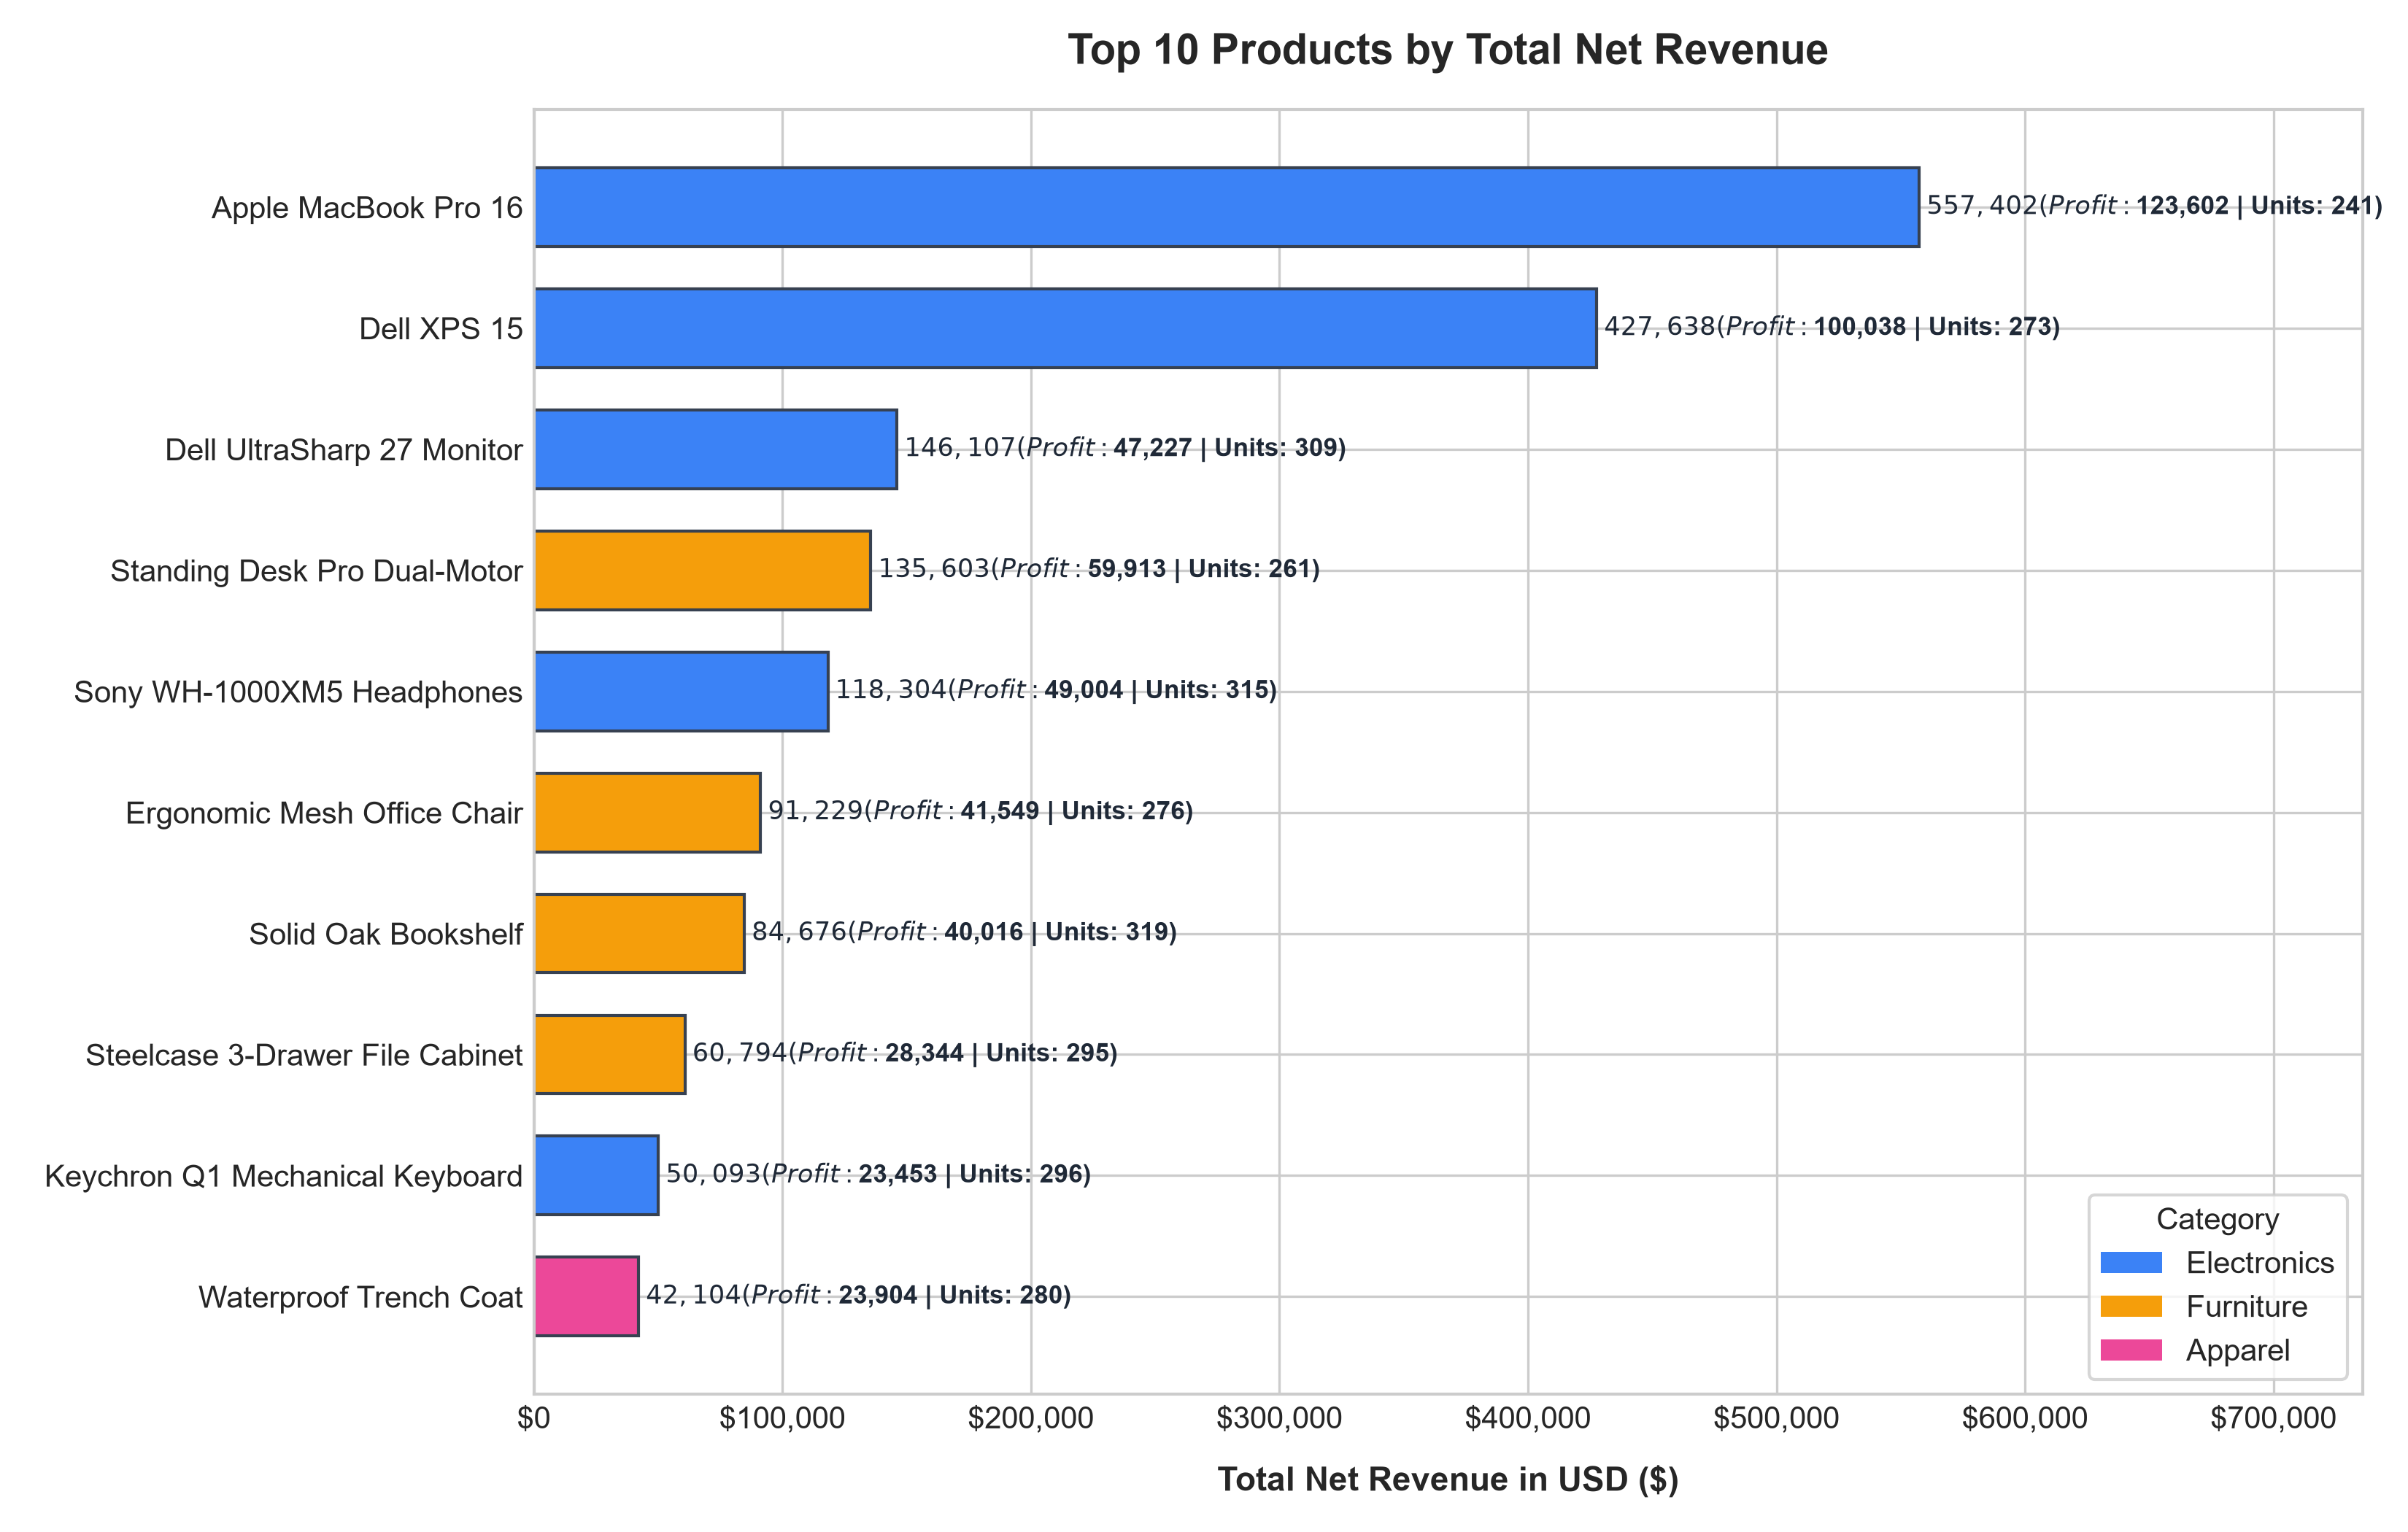

In [7]:
top_products = df.groupby(['Product_Name', 'Category']).agg(
    Revenue=('Total_Revenue', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Quantity', 'sum')
).reset_index().sort_values(by='Revenue', ascending=False).head(10)
display(top_products)

## 9. Regional Performance Diagnostics

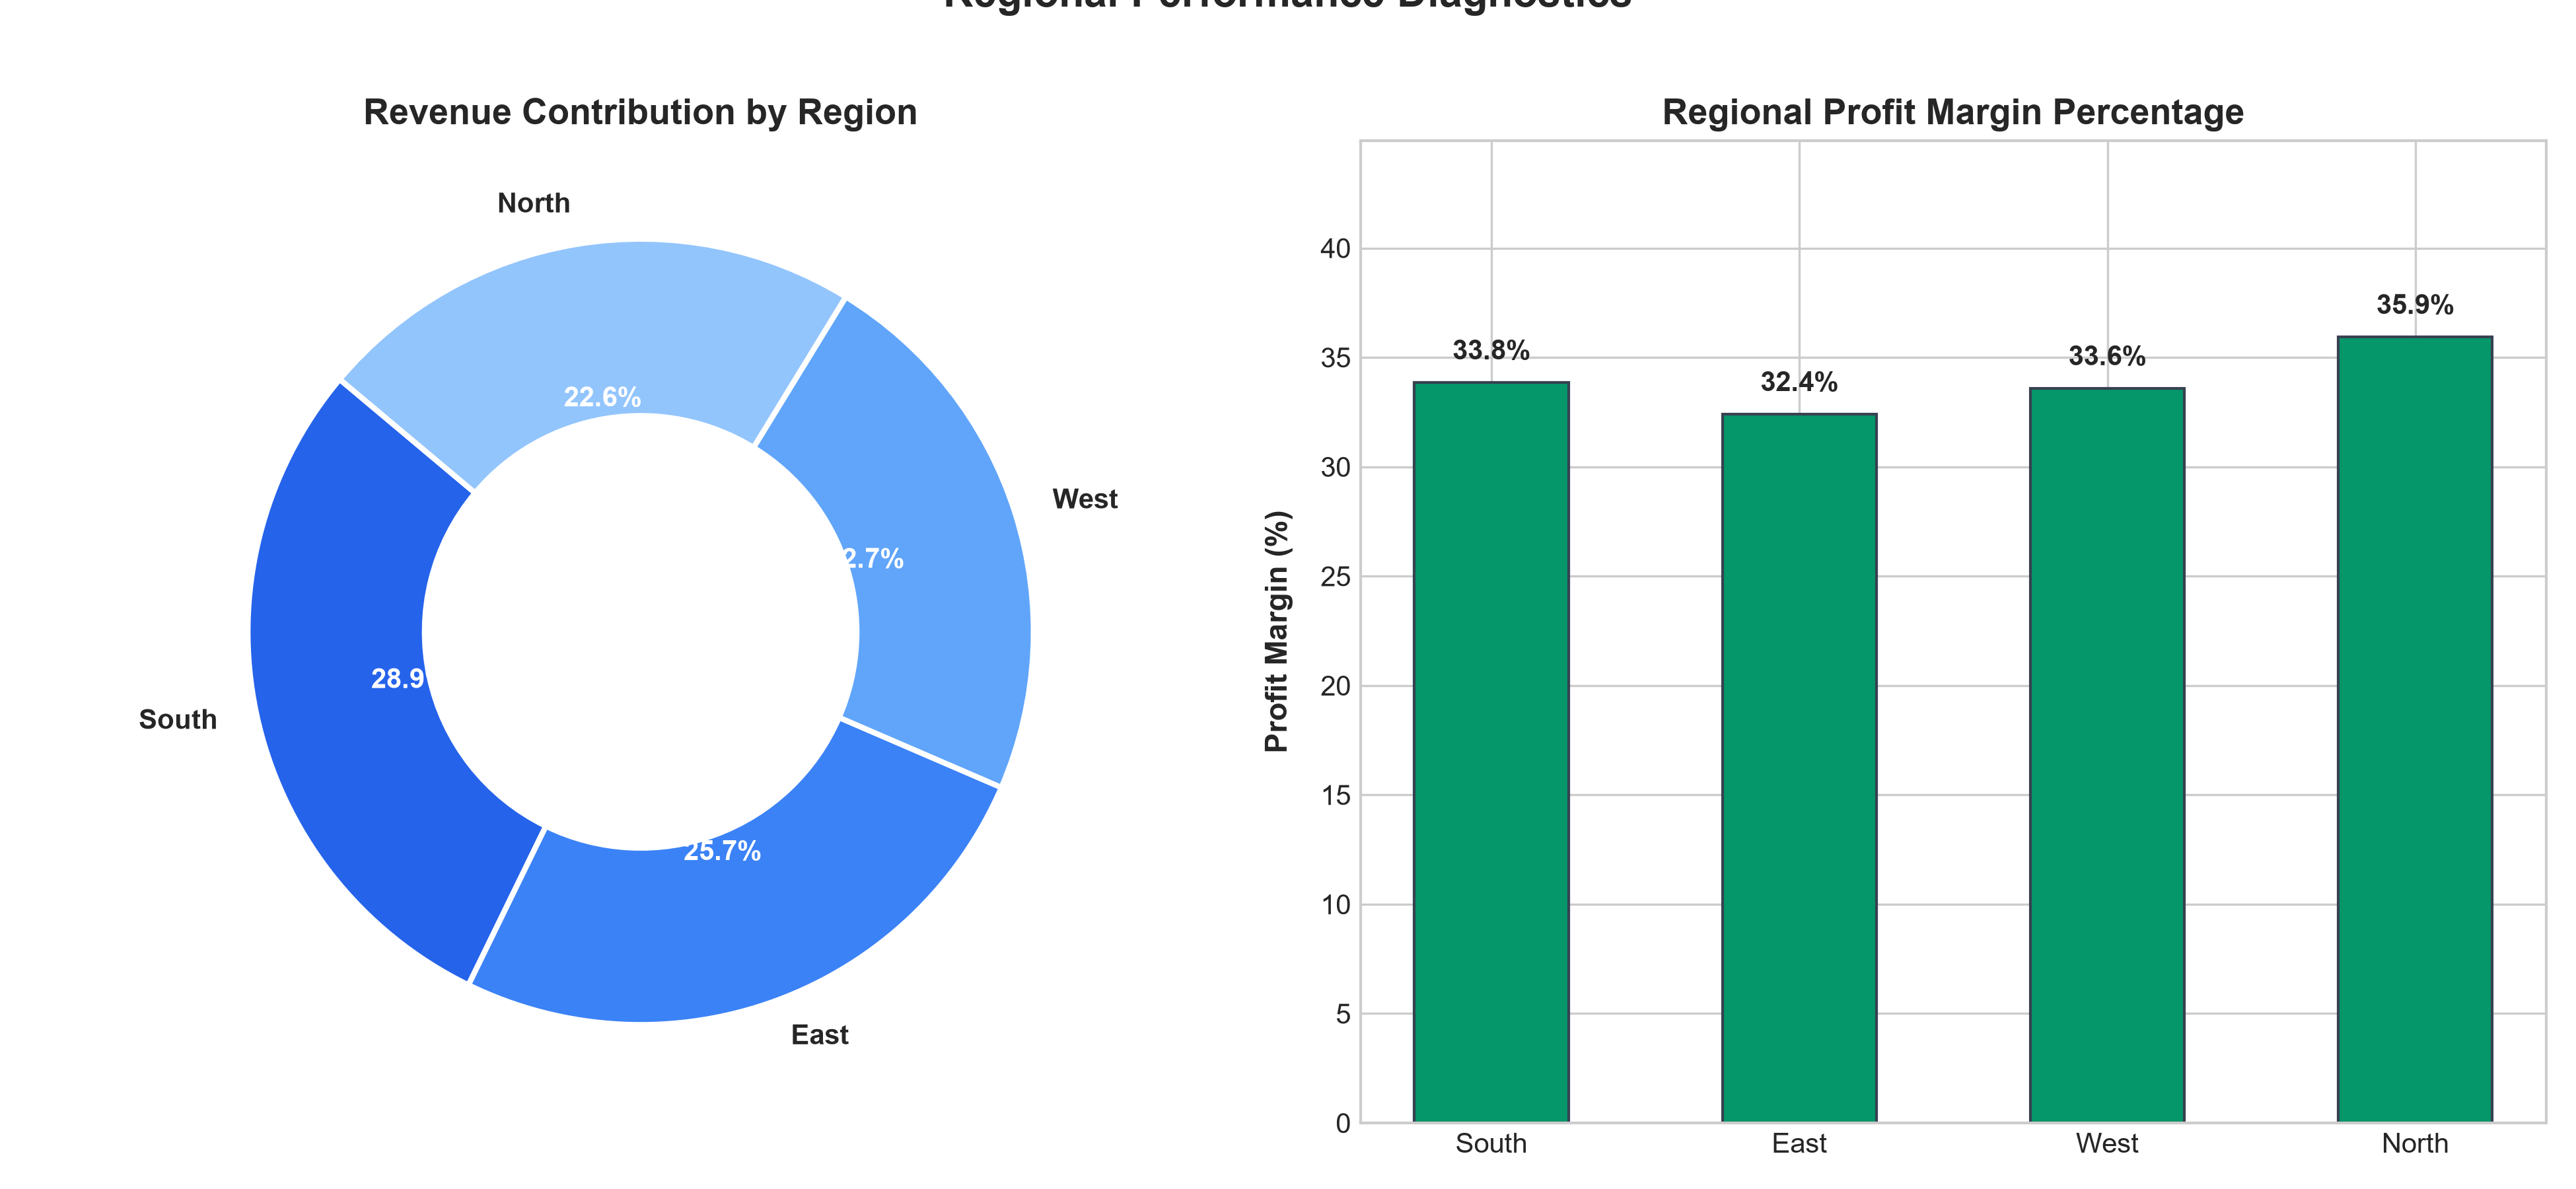

In [8]:
region_df = df.groupby('Region').agg(
    Revenue=('Total_Revenue', 'sum'),
    Profit=('Profit', 'sum'),
    Transactions=('Order_ID', 'count')
).reset_index()
region_df['Margin_Pct'] = (region_df['Profit'] / region_df['Revenue']) * 100
display(region_df.sort_values(by='Revenue', ascending=False))

## 10. Discount Analysis: Profit Margin Erosion
Quantifying the impact of heavy discounting on company margins.

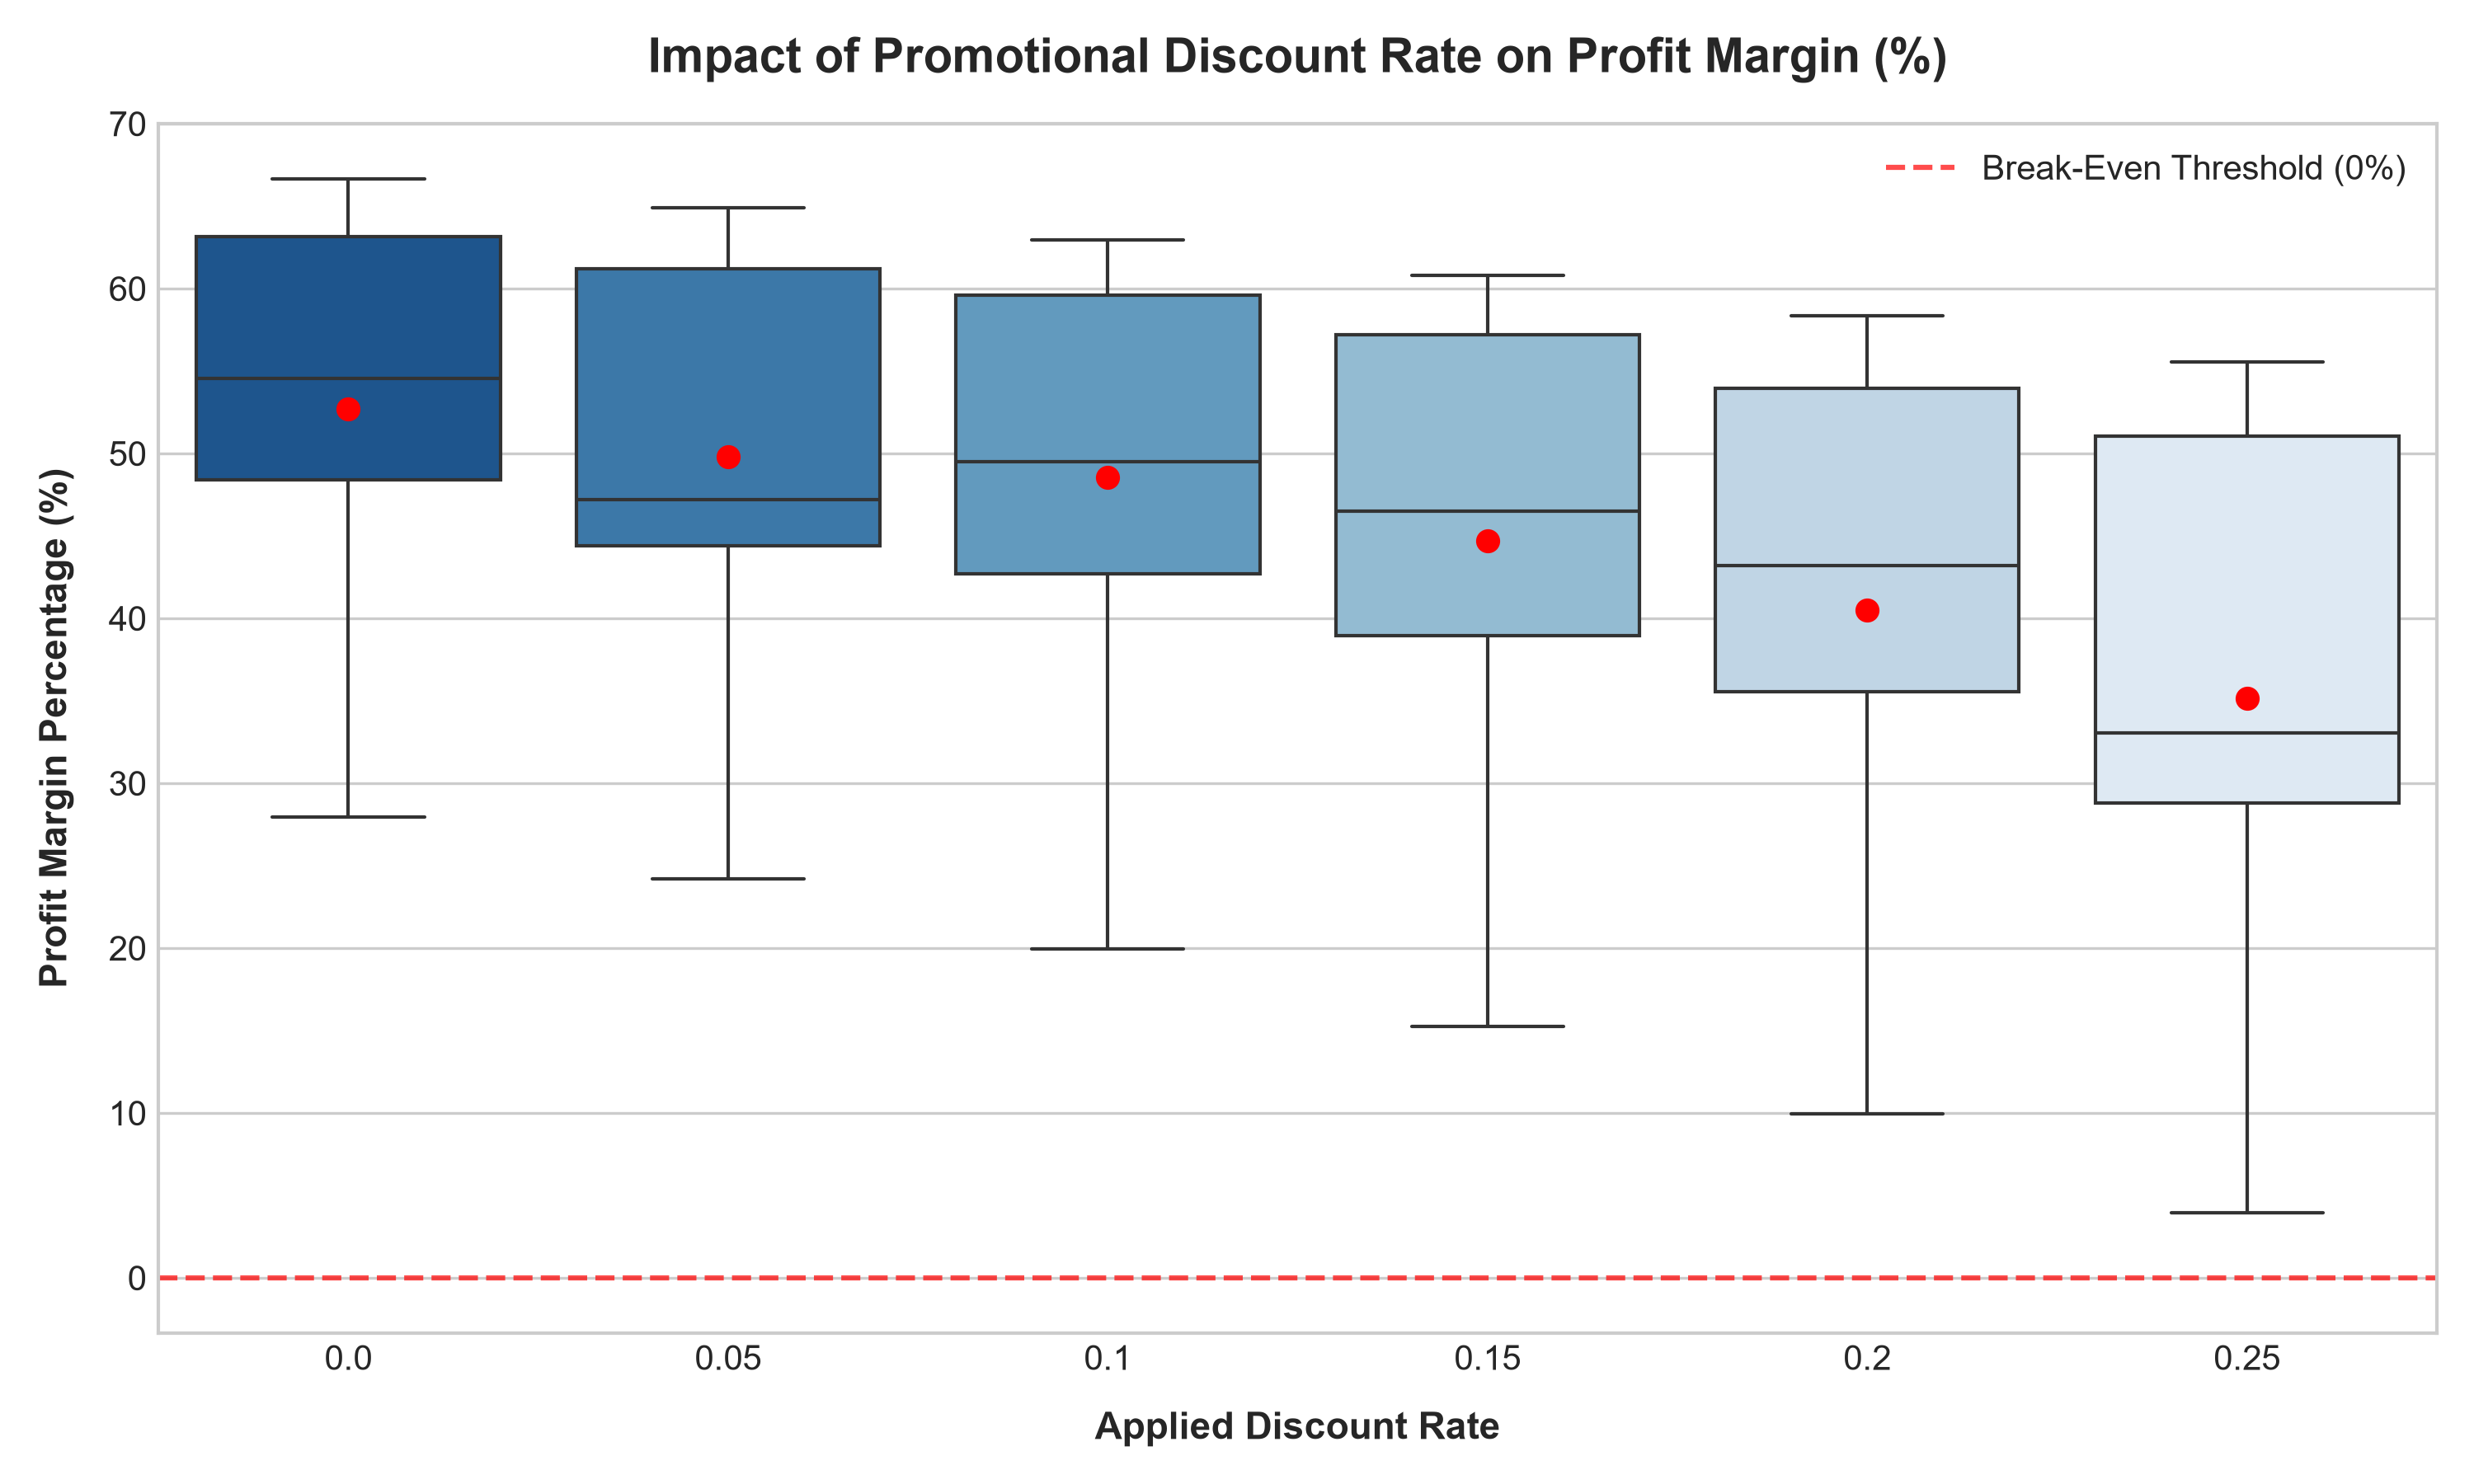

In [9]:
disc_perf = df.groupby('Discount').agg(
    Orders=('Order_ID', 'count'),
    Revenue=('Total_Revenue', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Margin=('Profit_Margin_Pct', 'mean')
).reset_index()
display(disc_perf)

## 11. Key Business Insights & Strategic Recommendations

### 💡 Key Findings:
1. **Electronics Drives High Top-Line Volume but Lower Margin (26.89%):**
   - Generated **$1,325,521.70** (69.8% of total revenue) and **$356,431.70** in profit.
   - Laptops (MacBook Pro 16 & Dell XPS 15) represent over $985k in gross sales alone.
2. **Apparel & Office Supplies Boast Exceptional Margin Efficiency (>54%):**
   - Apparel delivered a **60.05%** margin ($83.3k profit on $138.7k revenue).
   - Office supplies yielded a **54.35%** margin with recurring demand.
3. **Geographic Balance with South in the Lead:**
   - South generated **$548,525.20** across 624 orders, maintaining a healthy 33.84% margin.
   - North had the highest regional margin efficiency at **35.92%**.
4. **Excessive Discounting Compresses Margins Dramatically:**
   - Full-price sales (0% discount) enjoy a **52.68%** average profit margin.
   - Orders discounted at 20-25% suffer severe margin compression down to **35.13%**, generating only $10.3k in profit across 100 transactions.

### 🎯 Strategic Recommendations:
1. **Implement Discount Caps on High-Cost Hardware:** Restrict discounts on Electronics (especially laptops) to a strict 10% ceiling to safeguard dollar margins.
2. **Cross-Selling High-Margin Accessories:** Bundle high-margin items (Apparel, Ergonomic Accessories, Keyboards) with low-margin laptop purchases at checkout to boost blended cart margin.
3. **Targeted Regional Growth in North:** Expand promotional outreach in the North region, which holds the highest operating profit margin (35.92%).
4. **Automated B2B Contract Discounts:** Transition Corporate and Home Office segments to tiered volume rebates rather than flat upfront transaction discounts.